# Multi-event Hansen research and paired model validation

This notebook evaluates the complete reviewed mining cohort at the event level while treating `sample_id` as the statistical grouping unit. It validates the previously frozen small-event thresholds on the newly reviewed points, compares RemoteCLIP and XGBoost with paired clustered bootstrap, studies dominant-year selection, and tests whether adjacent Hansen years can be interpreted as fragments of one physical event.

FIRMS is intentionally not inferred because it is not integrated into the current data pipeline.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, Markdown, display
from sqlalchemy import create_engine
from sqlalchemy.orm import Session

PROJECT_ROOT = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / 'Scripts' / 'ResearchTool').exists()
)
SCRIPTS_ROOT = PROJECT_ROOT / 'Scripts'
if str(SCRIPTS_ROOT) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_ROOT))

from ResearchScripts.ml_tests.config import load_config
from ResearchScripts.ml_tests.multi_event_research import (
    load_hansen_mask_paths,
    run_multi_event_research,
)
from ResearchScripts.ml_tests.rejection_diagnostics import (
    find_latest_latent_run,
    run_rejection_diagnostics,
)

pd.set_option('display.max_columns', 80)
pd.set_option('display.max_colwidth', 140)

## Configuration

The baseline run contains the first reviewed batch used to choose the small-event thresholds. Those point identifiers are excluded from threshold validation, so the second reviewed batch acts as an independent holdout.

In [2]:
REVIEWER_NAME = 'Olga'
PROFILE = 'quick'
RANDOM_SEED = 42
BOOTSTRAP_RUNS = 2000
BASELINE_RUN_DIR = PROJECT_ROOT / 'Scripts/ResearchScripts/Outputs/ml_experiments/reviewer_validation/20261108_224344'
LATENT_RUN_DIR = None

config = load_config(profile=PROFILE)
database_path = config.path_value('database').resolve()
ml_output_root = config.path_value('output_root').resolve()
latent_run_dir = Path(LATENT_RUN_DIR).resolve() if LATENT_RUN_DIR else find_latest_latent_run(ml_output_root)
baseline_event_path = BASELINE_RUN_DIR / 'event_level.csv'
baseline_sample_ids = set(pd.read_csv(baseline_event_path)['sample_id'].astype(str))

print(f'Database: {database_path}')
print(f'Latent run: {latent_run_dir}')
print(f'Frozen-threshold baseline points: {len(baseline_sample_ids)}')

Database: C:\Users\Hp\OneDrive\Рабочий стол\учёба\ML\ML-SbPSTU-2026\Scripts\ResearchTool\Data\forest\state.sqlite
Latent run: C:\Users\Hp\OneDrive\Рабочий стол\учёба\ML\ML-SbPSTU-2026\Scripts\ResearchScripts\Outputs\ml_experiments\20261101_184450
Frozen-threshold baseline points: 49


## Build the joined event table and run the research

The existing rejection-diagnostics pipeline remains the source of the normalized human hierarchy, model outputs, acquisition statistics, latent-space features, and QC fields. This notebook only adds the multi-event analyses that are not already implemented there.

C:\Users\Hp\OneDrive\Рабочий стол\учёба\ML\ML-SbPSTU-2026\Scripts\ResearchScripts\ml_tests\multi_event_research.py:1654: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  figure, axis = plt.subplots(figsize=(11, 5), constrained_layout=True)


Report directory: C:\Users\Hp\OneDrive\Рабочий стол\учёба\ML\ML-SbPSTU-2026\Scripts\ResearchScripts\Outputs\ml_experiments\multi_event_research\20261115_143510


,value
reviewed_events,260
reviewed_points,99
valid_events,138
rejected_events,122
multi_event_points,81
generated_at,2026-11-15T11:35:10.821079+00:00


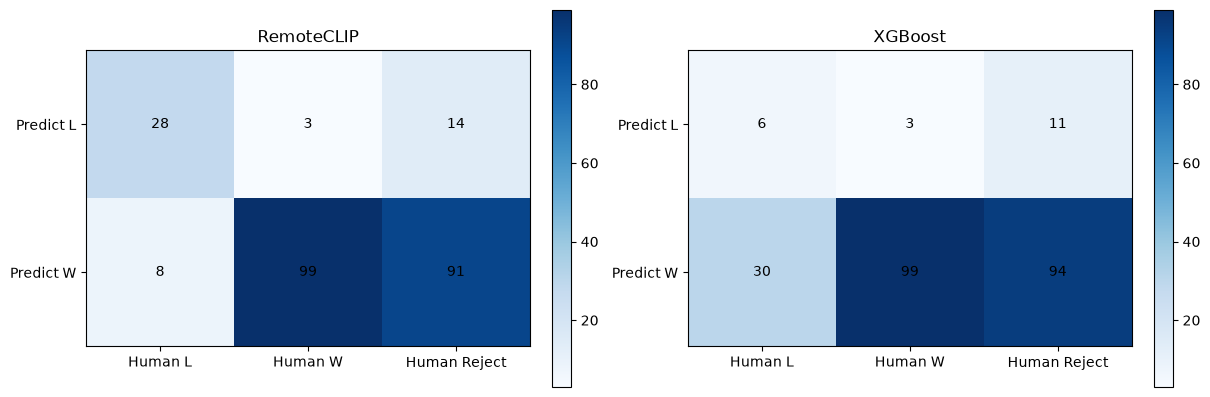

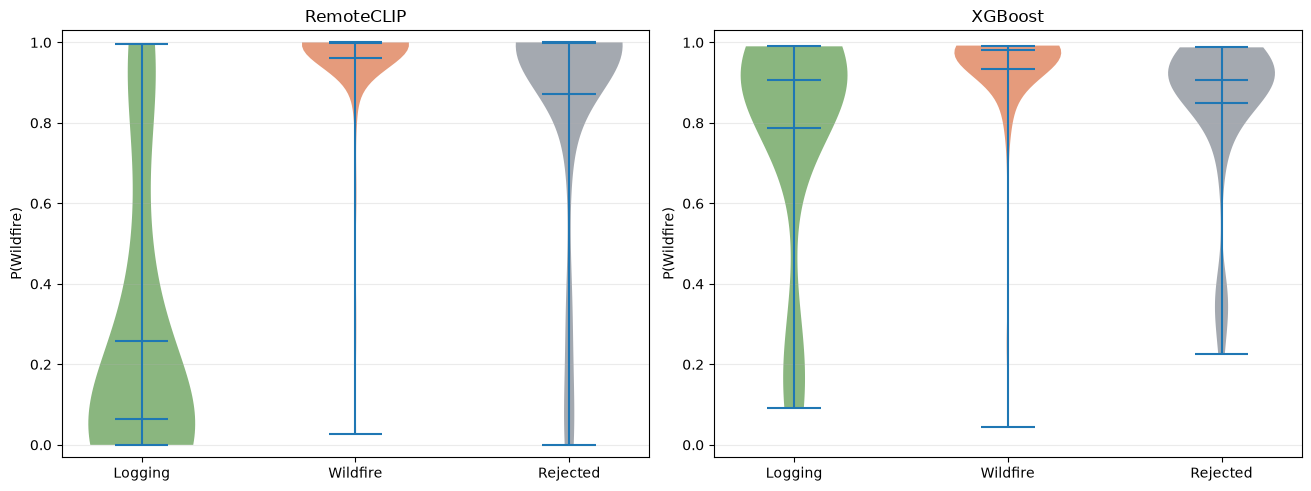

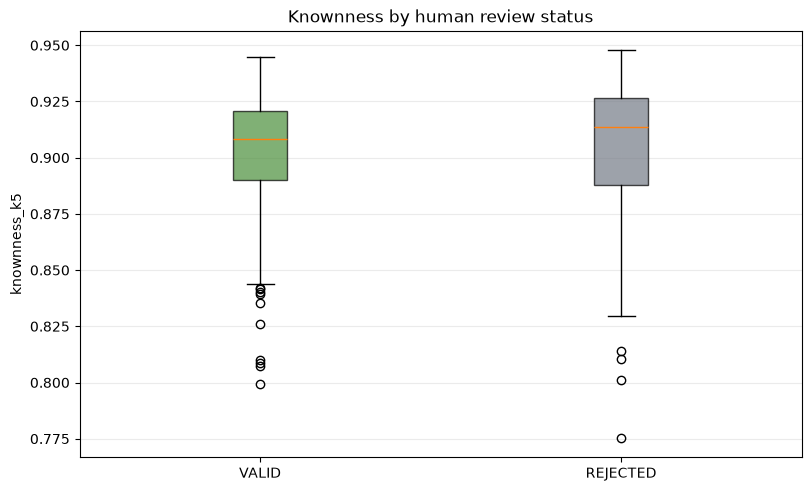

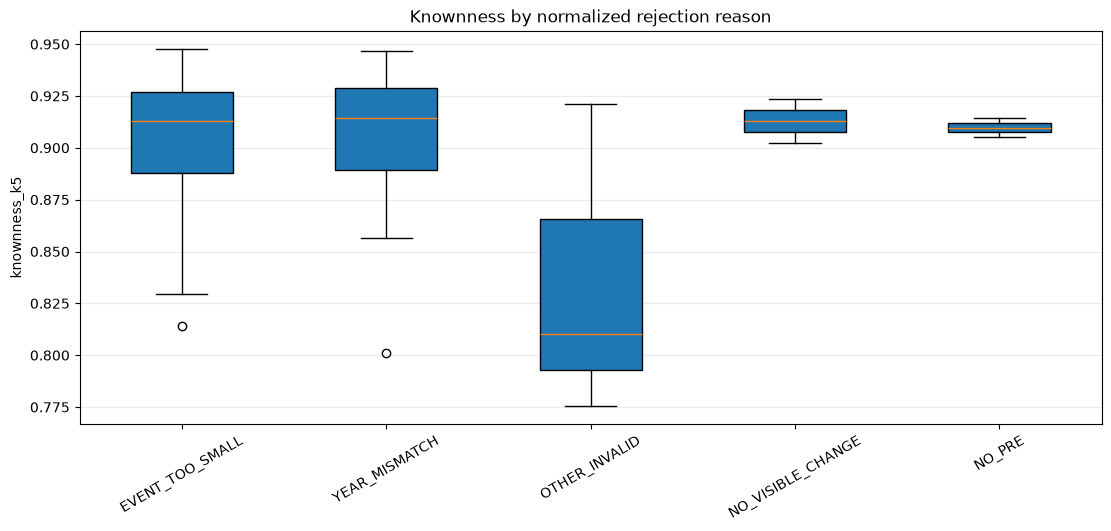

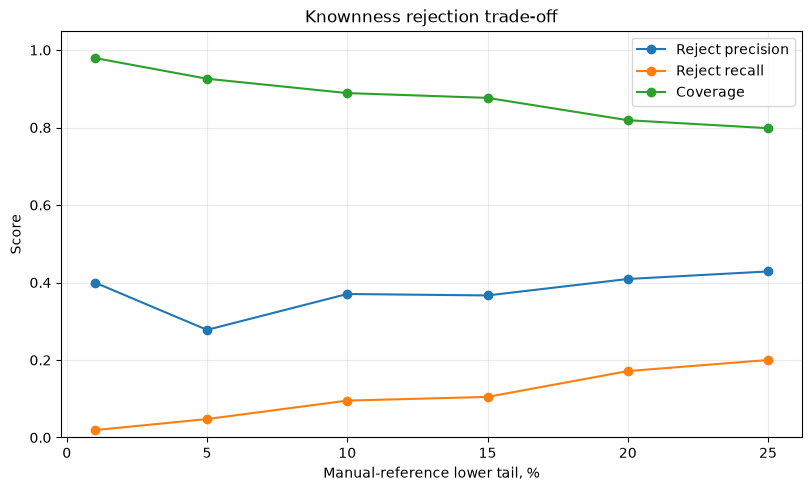

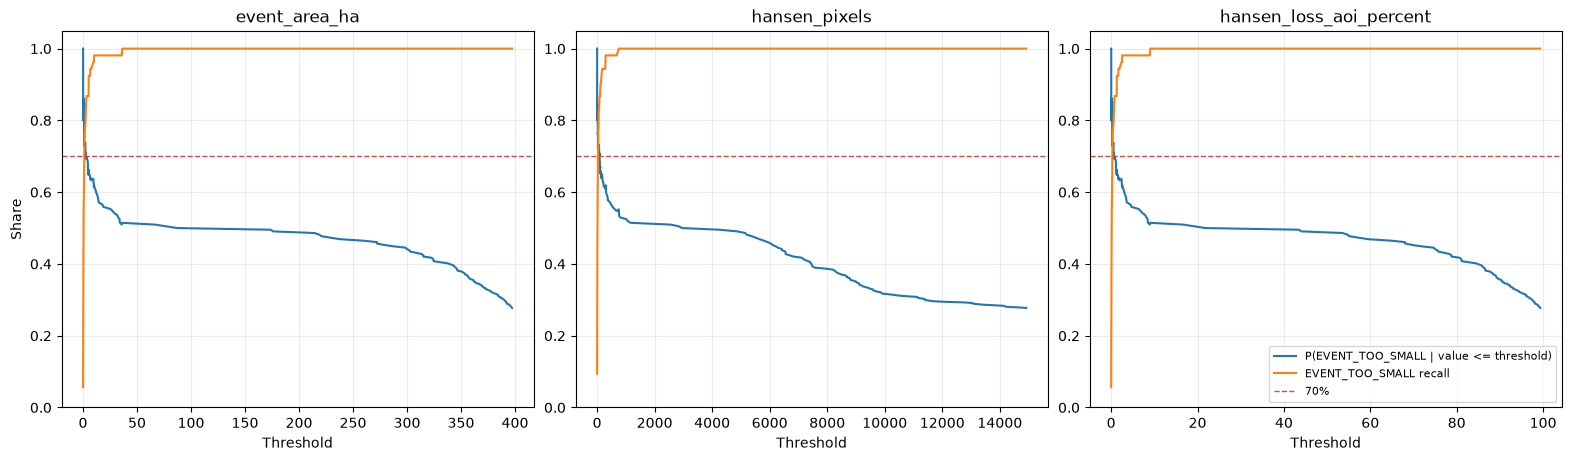

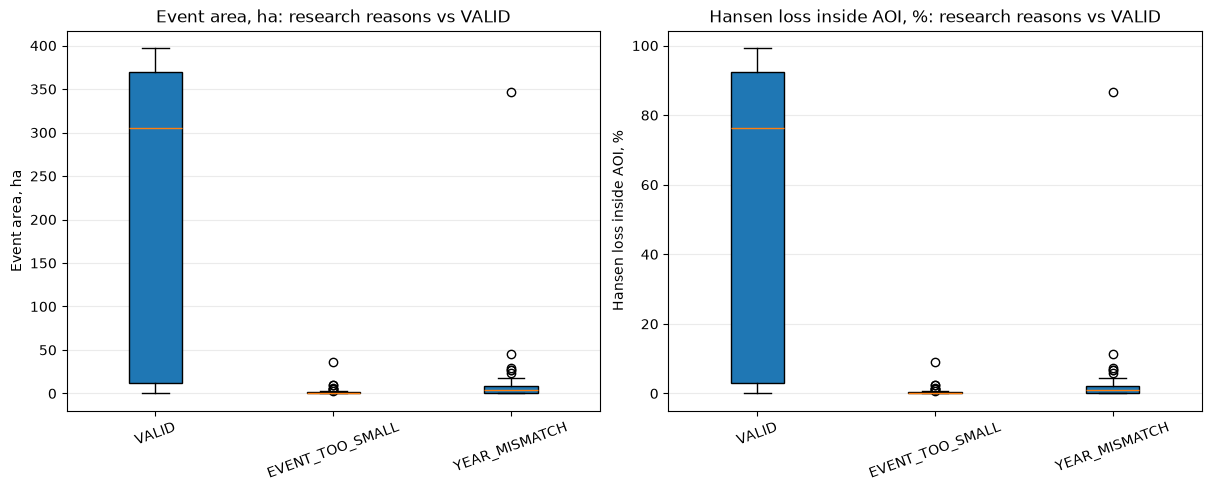

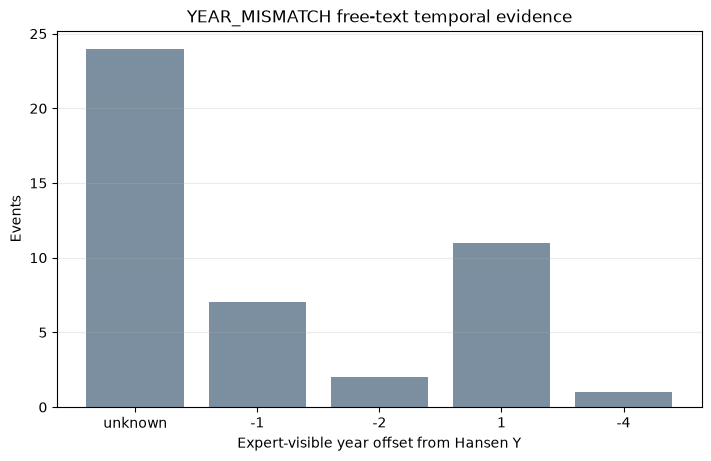

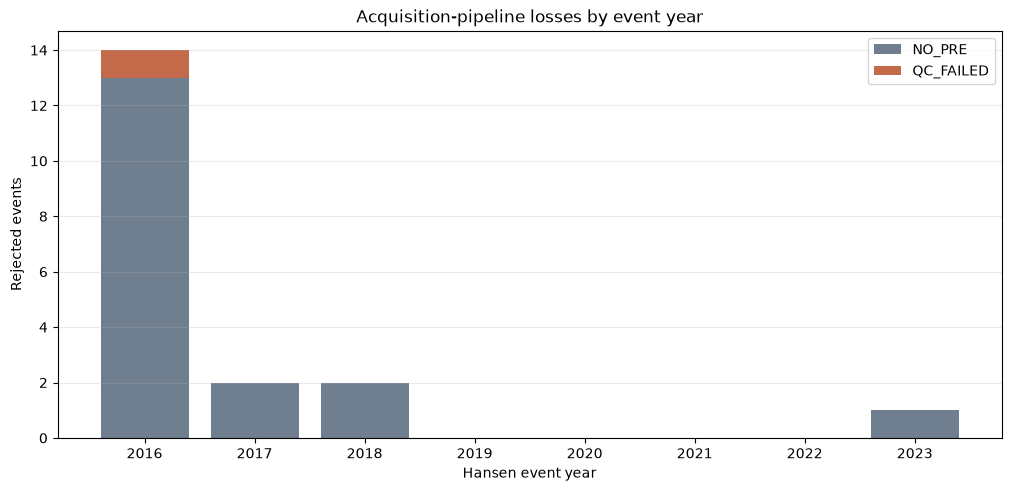

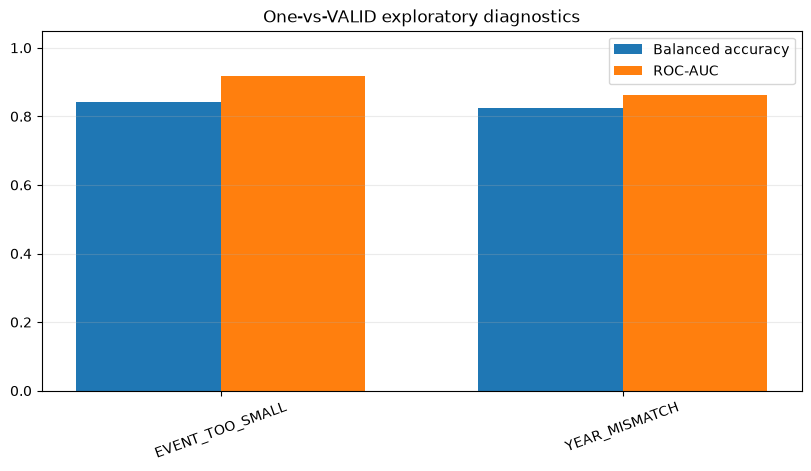

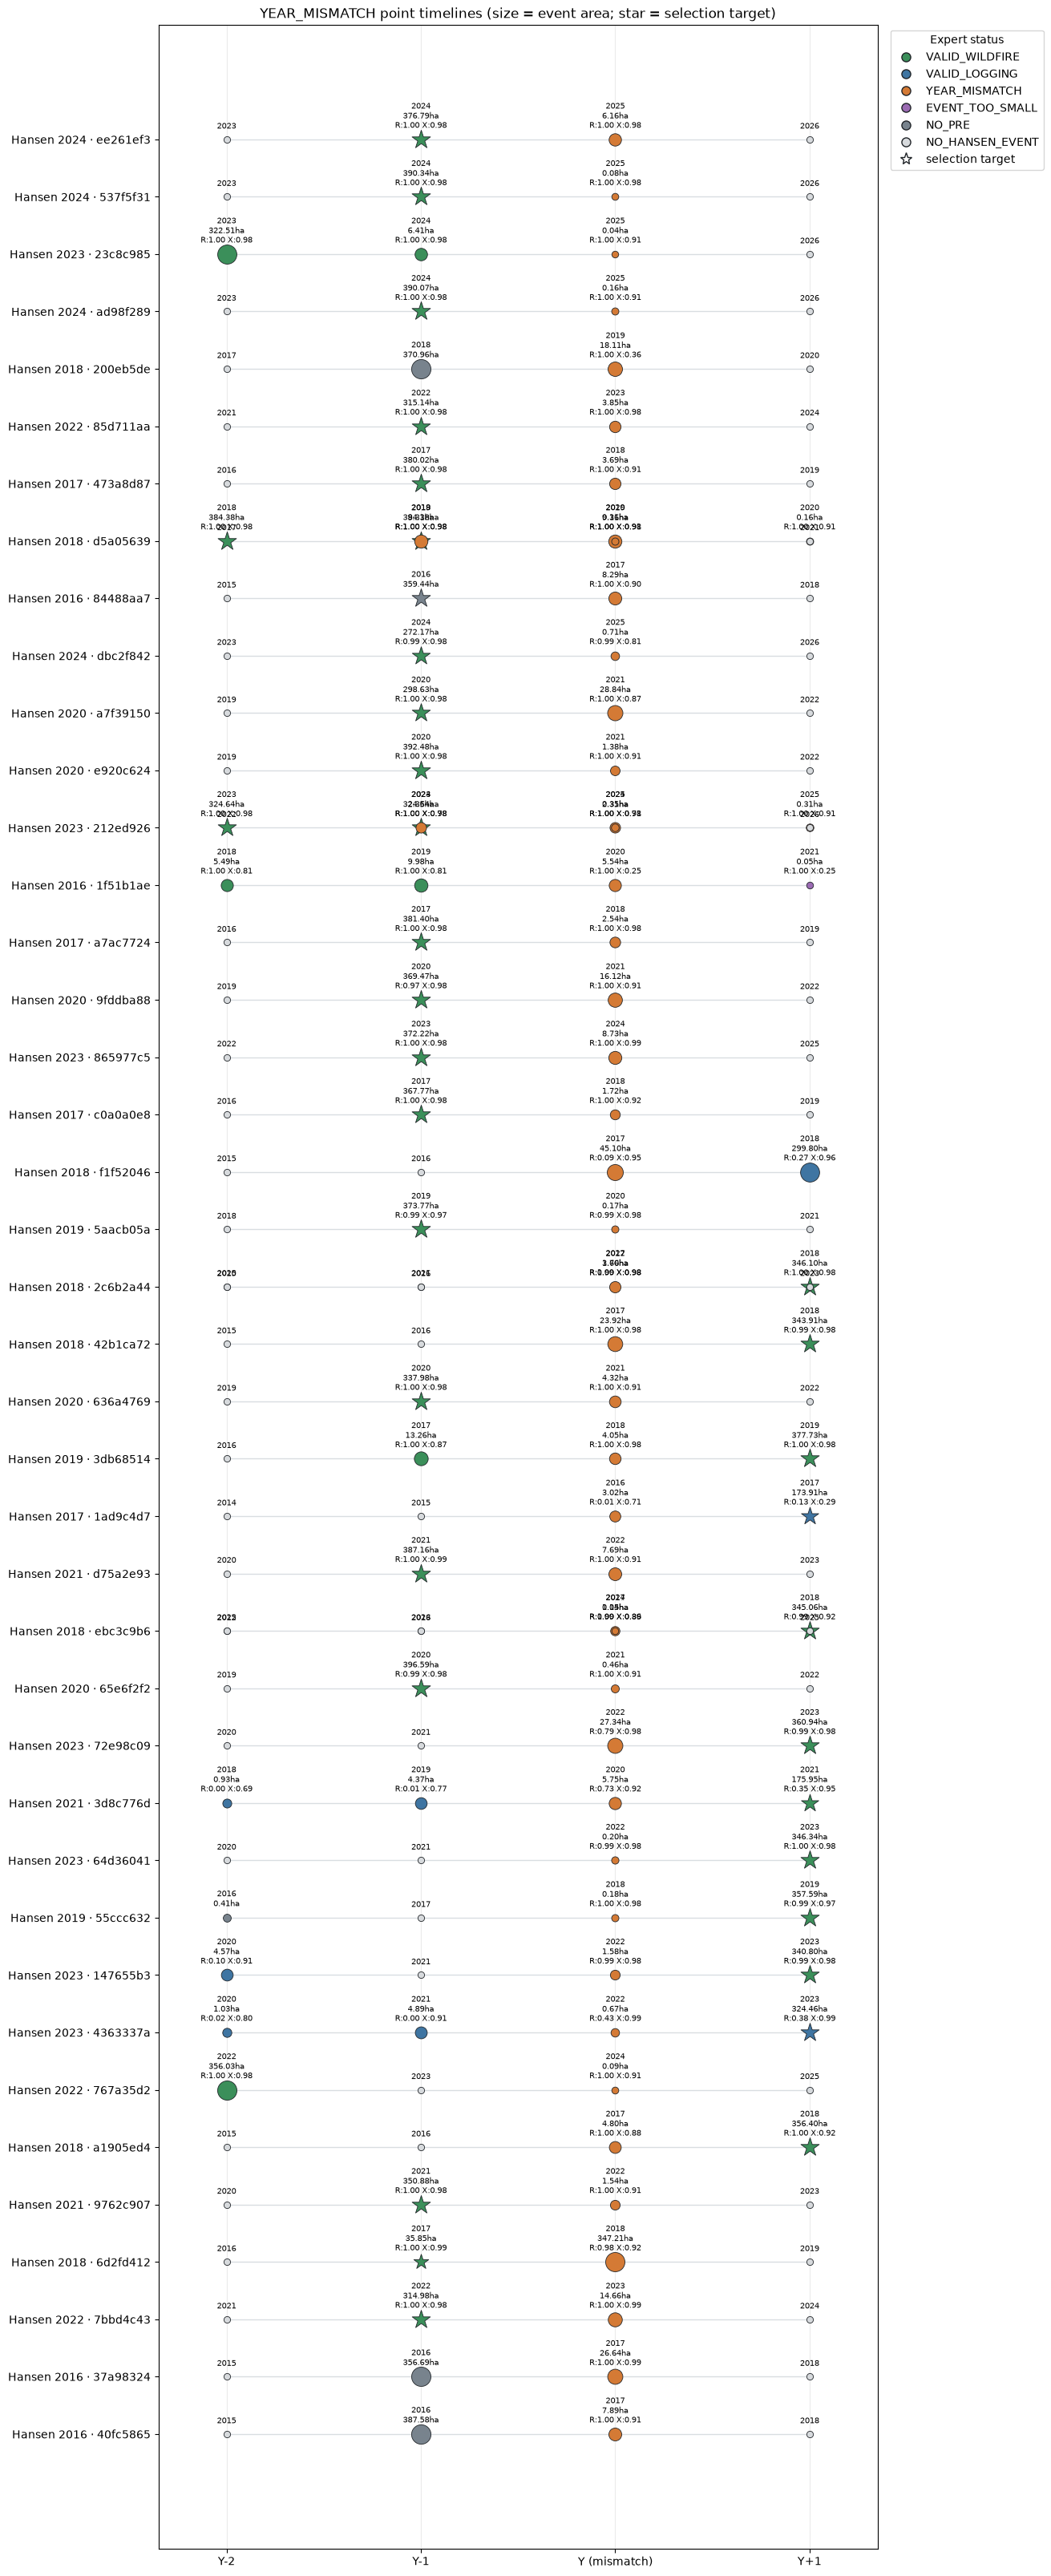

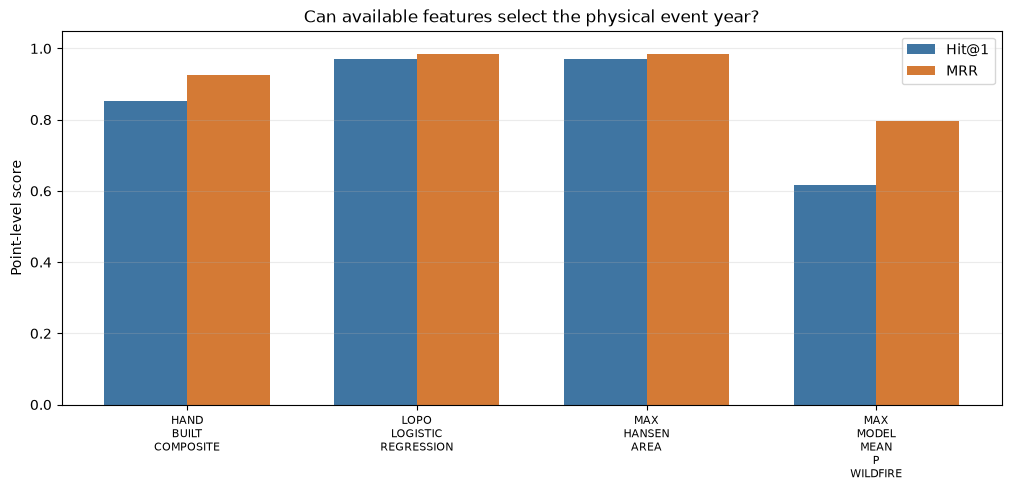

In [3]:
engine = create_engine(f'sqlite:///{database_path.as_posix()}', future=True)
with Session(engine) as db:
    base = run_rejection_diagnostics(
        db,
        reviewer_name=REVIEWER_NAME,
        latent_run_dir=latent_run_dir,
        output_root=ml_output_root / 'rejection_diagnostics',
        seed=RANDOM_SEED,
    )
    mask_paths = load_hansen_mask_paths(
        db,
        {str(row['sample_id']) for row in base['event_rows']},
    )
    result = run_multi_event_research(
        base['event_rows'],
        baseline_sample_ids=baseline_sample_ids,
        mask_paths=mask_paths,
        bootstrap_runs=BOOTSTRAP_RUNS,
        seed=RANDOM_SEED,
        output_root=ml_output_root / 'multi_event_research',
        base_diagnostics=base,
        base_report_dir=base['run_dir'],
    )

run_dir = Path(result['run_dir'])
print(f'Report directory: {run_dir}')
display(pd.DataFrame([result['summary']]).T.rename(columns={0: 'value'}))

## Reviewed cohort and normalized hierarchy

In [4]:
display(pd.DataFrame(result['hierarchy_counts']))
display(pd.DataFrame(result['taxonomy']['event_count_distribution']))
display(pd.DataFrame(result['taxonomy']['taxonomy_rows']))

,review_hierarchy_class,count,percent
0,VALID_WILDFIRE,102,39.230769
1,EVENT_TOO_SMALL,53,20.384615
2,YEAR_MISMATCH,45,17.307692
3,VALID_LOGGING,36,13.846154
4,NO_PRE,18,6.923077
5,OTHER_INVALID,3,1.153846
6,NO_VISIBLE_CHANGE,2,0.769231
7,QC_FAILED,1,0.384615


,events_per_point,points,percent
0,1,18,18.181818
1,2,44,44.444444
2,3,19,19.191919
3,4,5,5.050505
4,5,5,5.050505
5,6,5,5.050505
6,7,2,2.020202
7,8,1,1.010101


,point_type,points,share_multi_event_points,mean_event_count
0,SINGLE_PHYSICAL_EVENT_WITH_TEMPORAL_TAILS,29,35.802469,2.413793
1,REPEATED_SAME_CLASS,23,28.395062,3.739130
2,DOMINANT_EVENT_WITH_SMALL_COMPONENTS,12,14.814815,2.416667
3,UNRESOLVED,10,12.345679,2.100000
4,TRUE_CLASS_CHANGE,7,8.641975,5.142857


## Paired RemoteCLIP vs XGBoost validation

All deltas are computed on the same valid events. Confidence intervals resample complete points, not individual events, which preserves within-point dependence.

In [5]:
display(pd.DataFrame(result['paired_models']['metric_rows']))
display(pd.DataFrame(result['paired_models']['joint_outcomes']))

,metric,remoteclip,xgboost,point_delta,bootstrap_runs,mean_delta,median_delta,ci_low,ci_high,probability_delta_gt_zero
0,accuracy,0.920290,0.760870,0.159420,2000,0.159135,0.158730,0.073166,0.250000,1.0000
1,balanced_accuracy,0.874183,0.568627,0.305556,2000,0.312804,0.313914,0.184804,0.435832,1.0000
2,macro_f1,0.891595,0.561905,0.329690,2000,0.348656,0.346651,0.170796,0.505119,1.0000
3,recall_logging,0.777778,0.166667,0.611111,2000,0.626240,0.627907,0.375000,0.862108,1.0000
4,recall_wildfire,0.970588,0.970588,0.000000,2000,-0.000633,0.000000,-0.061856,0.063658,0.4255


,joint_outcome,count,percent
0,BOTH_CORRECT,102,73.913043
1,REMOTECLIP_ONLY_CORRECT,25,18.115942
2,BOTH_WRONG,8,5.797101
3,XGBOOST_ONLY_CORRECT,3,2.173913


## Independent validation of the frozen EVENT_TOO_SMALL rules

The thresholds were selected before the second review batch: area $\leq 3.285$ ha, Hansen pixels $\leq 84$, or Hansen loss inside AOI $\leq 0.821\%$. The valid-loss rate is shown explicitly because it determines whether a rule is safe for automatic exclusion.

In [6]:
display(pd.DataFrame([result['fixed_small_event_validation']['summary']]).T.rename(columns={0: 'value'}))
display(pd.DataFrame(result['fixed_small_event_validation']['metrics']))

,value
validation_points,50
validation_events,158
baseline_points,49
thresholds_frozen_before_validation,True


,rule,threshold,events,event_too_small_events,predicted_small_events,true_positive,false_positive,false_negative,true_negative,precision,recall,specificity,f1,valid_events,valid_events_lost,valid_lost_rate,feature,missing_events
0,event_loss_area_ha <= 3.285,3.285,158,37,62,31,31,6,90,0.500000,0.837838,0.743802,0.626263,84,14,0.166667,event_loss_area_ha,0
1,event_hansen_pixels <= 84.0,84.000,158,37,60,31,29,6,92,0.516667,0.837838,0.760331,0.639175,84,13,0.154762,event_hansen_pixels,0
2,hansen_loss_aoi_percent <= 0.821,0.821,158,37,62,31,31,6,90,0.500000,0.837838,0.743802,0.626263,84,14,0.166667,hansen_loss_aoi_percent,0
3,ANY_FIXED_THRESHOLD,NaN,158,37,62,31,31,6,90,0.500000,0.837838,0.743802,0.626263,84,14,0.166667,combined_or,0


## Dominant-year ranking and dominant-relative structure

A point may contain more than one human-valid year. Therefore Hit@1, Hit@2, reciprocal rank, and year error use the set of all valid years as the target.

In [7]:
display(pd.DataFrame(result['ranking']['metrics']))
display(pd.DataFrame(result['dominant_relative']['summary_rows']))
display(pd.DataFrame(result['dominant_relative']['headline_rows']))
display(pd.DataFrame(result['dominant_relative']['relative_area_by_class']))

,method,eligible_points,hit_at_1,hit_at_2,mean_reciprocal_rank,median_target_rank,mean_year_error
0,HAND_BUILT_COMPOSITE,75,0.906667,1.000000,0.953333,1.0,0.226667
1,HISTORICAL_DOMINANT,75,0.933333,0.973333,0.962222,1.0,0.093333
2,LOPO_LOGISTIC_REGRESSION,75,0.933333,0.986667,0.963333,1.0,0.080000
3,MAX_HANSEN_AREA,75,0.933333,0.973333,0.962222,1.0,0.093333
4,MAX_MODEL_MEAN_P_WILDFIRE,75,0.773333,0.986667,0.883333,1.0,0.413333


,method,delta_year,events,points,valid_share,rejected_share,year_mismatch_share,event_too_small_share,logging_share,wildfire_share,median_relative_area,mean_remoteclip_p_wildfire,mean_xgboost_p_wildfire,model_disagreement_share
0,HAND_BUILT_COMPOSITE,-9,1,1,0.000000,1.000000,0.0,1.000000,0.000000,0.0,0.000662,0.173553,0.953252,1.0
1,HAND_BUILT_COMPOSITE,-8,1,1,1.000000,0.000000,0.0,0.000000,0.000000,1.0,8.320536,0.999775,0.788127,0.0
2,HAND_BUILT_COMPOSITE,-7,5,5,0.400000,0.600000,0.0,0.200000,0.200000,0.2,0.003302,0.655533,0.923954,0.6
3,HAND_BUILT_COMPOSITE,-6,6,6,0.666667,0.333333,0.0,0.166667,0.666667,0.0,0.004491,0.126242,0.894505,1.0
4,HAND_BUILT_COMPOSITE,-5,5,5,0.600000,0.400000,0.2,0.200000,0.600000,0.0,0.048055,0.277966,0.891007,0.8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82,MAX_MODEL_MEAN_P_WILDFIRE,3,5,5,0.200000,0.800000,0.0,0.600000,0.200000,0.0,0.026337,0.758261,0.760280,0.0
83,MAX_MODEL_MEAN_P_WILDFIRE,4,1,1,1.000000,0.000000,0.0,0.000000,1.000000,0.0,0.066656,0.007586,0.213646,0.0
84,MAX_MODEL_MEAN_P_WILDFIRE,6,2,2,0.000000,1.000000,0.5,0.500000,0.000000,0.0,0.000462,0.998805,0.358591,1.0
85,MAX_MODEL_MEAN_P_WILDFIRE,7,2,2,0.500000,0.500000,0.0,0.500000,0.500000,0.0,0.161171,0.499913,0.239379,0.5


,method,stratum,outcome,events,points,estimate,ci_low,ci_high
0,HISTORICAL_DOMINANT,delta_0,VALID,75,75,0.933333,0.866667,0.986667
1,HISTORICAL_DOMINANT,delta_0,YEAR_MISMATCH,75,75,0.013333,0.000000,0.040000
2,HISTORICAL_DOMINANT,delta_0,EVENT_TOO_SMALL,75,75,0.000000,0.000000,0.000000
3,HISTORICAL_DOMINANT,abs_delta_1,VALID,84,70,0.285714,0.192308,0.377785
4,HISTORICAL_DOMINANT,abs_delta_1,YEAR_MISMATCH,84,70,0.392857,0.298851,0.493671
5,HISTORICAL_DOMINANT,abs_delta_1,EVENT_TOO_SMALL,84,70,0.250000,0.162500,0.333333
6,MAX_HANSEN_AREA,delta_0,VALID,75,75,0.933333,0.866667,0.986667
7,MAX_HANSEN_AREA,delta_0,YEAR_MISMATCH,75,75,0.013333,0.000000,0.040000
8,MAX_HANSEN_AREA,delta_0,EVENT_TOO_SMALL,75,75,0.000000,0.000000,0.000000
9,MAX_HANSEN_AREA,abs_delta_1,VALID,84,70,0.285714,0.192308,0.377785


,review_class,events,median_relative_area,mean_relative_area,p25_relative_area,p75_relative_area
0,VALID_LOGGING,36,0.019960,0.245802,0.003271,0.108036
1,VALID_WILDFIRE,85,1.000000,0.746509,0.192524,1.000000
2,YEAR_MISMATCH,41,0.007224,0.043039,0.001168,0.023452
3,EVENT_TOO_SMALL,51,0.001592,0.007160,0.000673,0.005580


## Merge simulation and spatial connectivity

The merge proposal is evaluated against human decisions; it is not written back to the database. Raster connectivity uses the per-year components of the existing AOI Hansen loss mask.

In [8]:
display(pd.DataFrame([result['merge_simulation']['summary']]).T.rename(columns={0: 'value'}))
display(pd.DataFrame([result['spatial_connectivity']['summary']]).T.rename(columns={0: 'value'}))
display(pd.DataFrame(result['spatial_connectivity']['type_summary']))

,value
rule,adjacent year and relative area <= 0.5
multi_event_points,81
adjacent_pairs,132
proposed_merges,126
good_merges,65
bad_merges,32
unresolved_merges,29
merge_precision_resolved,0.670103
merge_recall_identifiable_tails,0.970149
physical_events_before,242


,value
status,ok
multi_event_points,81
points_with_masks,79
adjacent_pairs_with_geometry,132
points_missing_masks,0
pairs_missing_year_components,0
distance_definition,distance between raster pixel centers in local metre approximation


,pair_type,pairs,median_minimum_distance_m,median_centroid_distance_m,touching_1px_share,touching_2px_share,median_relative_area
0,OTHER,30,15.684361,459.661699,0.866667,0.900000,0.036033
1,VALID_PLUS_EVENT_TOO_SMALL,28,15.261739,507.256882,0.964286,0.964286,0.007894
2,VALID_PLUS_VALID_SAME_CLASS,35,16.218316,485.100232,0.771429,0.800000,0.104086
3,VALID_PLUS_YEAR_MISMATCH,39,14.034661,535.611043,0.974359,1.000000,0.012216


## Acquisition, knownness, and exploratory validity diagnostics

`NO_PRE` and `QC_FAILED` are reported as acquisition-pipeline losses rather than classification targets. The validity models are exploratory and use grouped cross-validation.

In [9]:
display(pd.DataFrame(base['acquisition_pipeline']['summary']))
display(pd.DataFrame(base['knownness_status_summary']))
display(pd.DataFrame(base['validity_models'].get('metrics', [])))

,reason,events,points,median_pre_count,median_event_count,median_post_count,median_usable_pre_count,median_usable_post_count,bad_cloud_downloads,bad_quality_downloads,manually_excluded_downloads,mean_cloud_fraction,mean_nodata_fraction
0,NO_PRE,18,16,0.0,3.5,6.5,0.0,2.5,73,114,151,0.161041,0.04738
1,QC_FAILED,1,1,0.0,1.0,8.0,0.0,0.0,6,9,9,0.146944,0.00000


,review_status,metric,count,mean,std,q05,q25,median,q75,q95
0,REJECTED,knownness_k5,105,0.903865,0.031983,0.856765,0.887648,0.913752,0.926393,0.938600
1,VALID,knownness_k5,138,0.900403,0.030239,0.840206,0.889914,0.908270,0.920912,0.933741


,model,events,samples,folds,accuracy,balanced_accuracy,precision_rejected,recall_rejected,f1_rejected,roc_auc,average_precision
0,LOGISTIC_REGRESSION,241,99,5,0.817427,0.824574,0.743802,0.873786,0.803571,0.892641,0.825293
1,XGBOOST,241,99,5,0.825726,0.825665,0.779817,0.825243,0.801887,0.903898,0.878333


## Generated figures

### Dominant Year Method Comparison

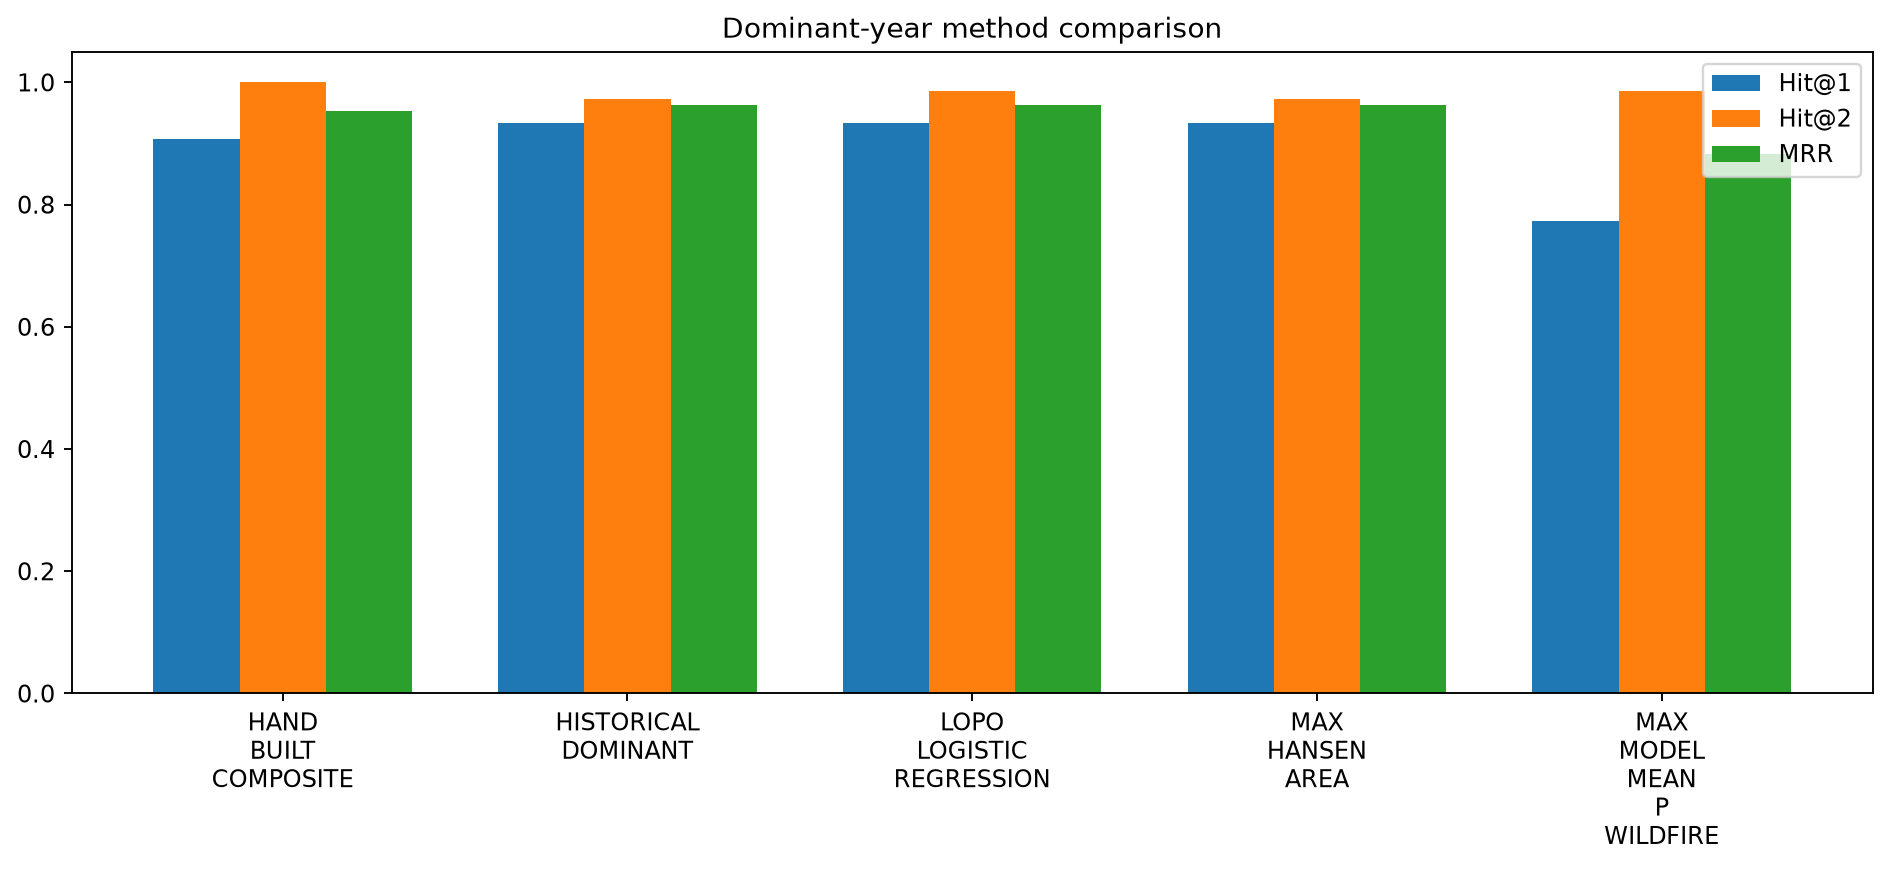

### Event Area By Review Status

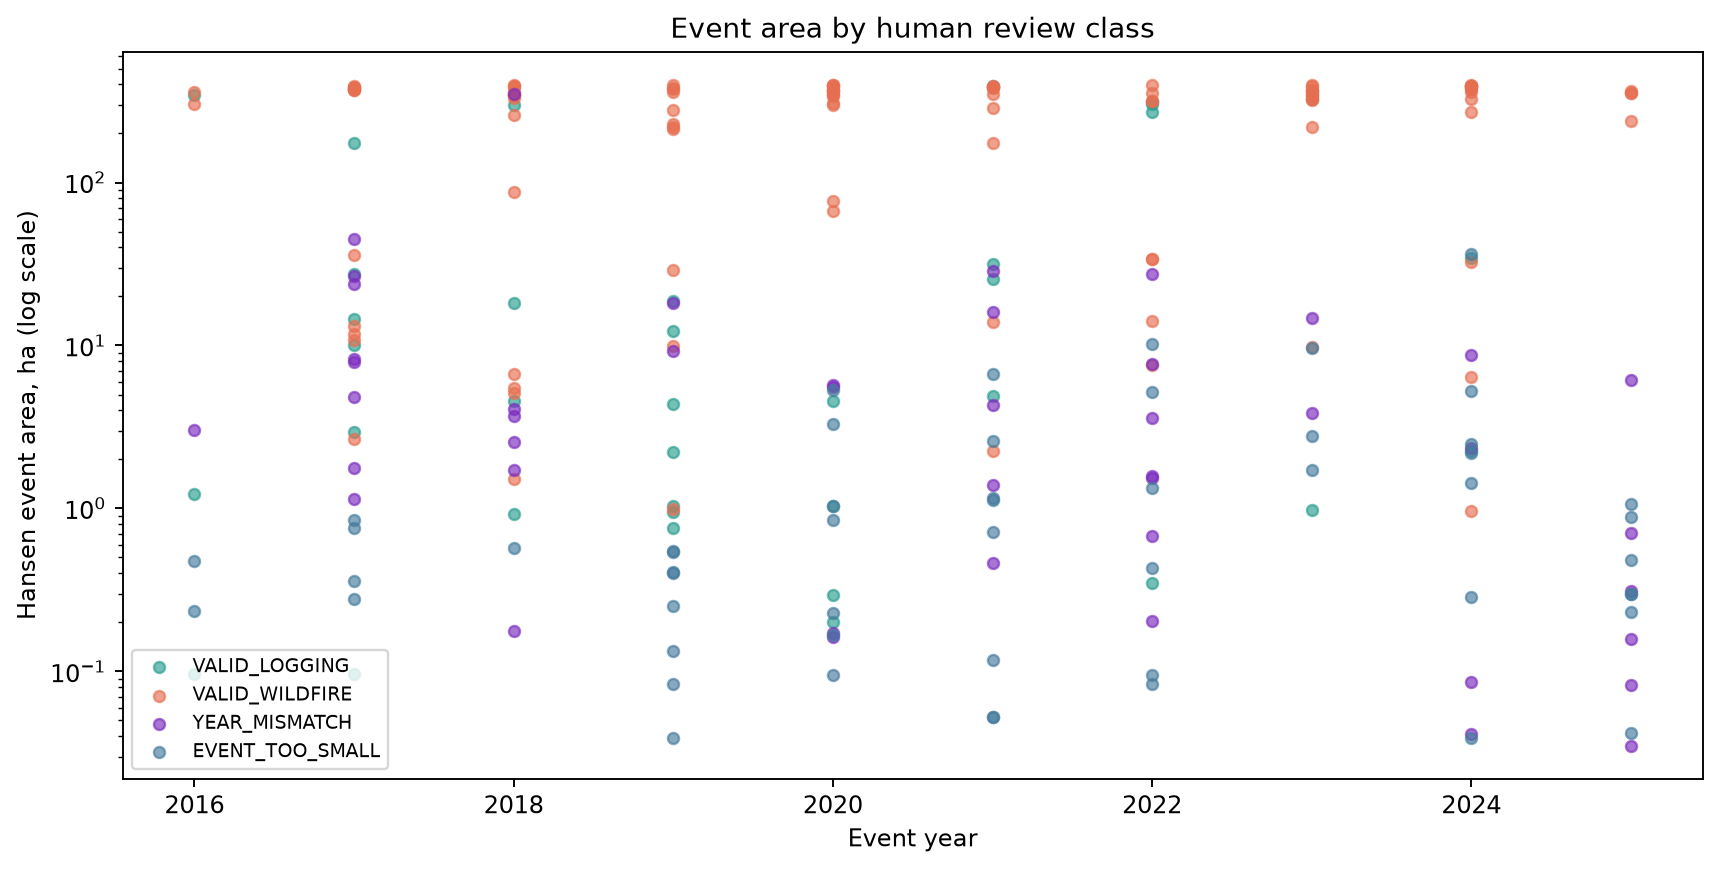

### Multi Event Taxonomy

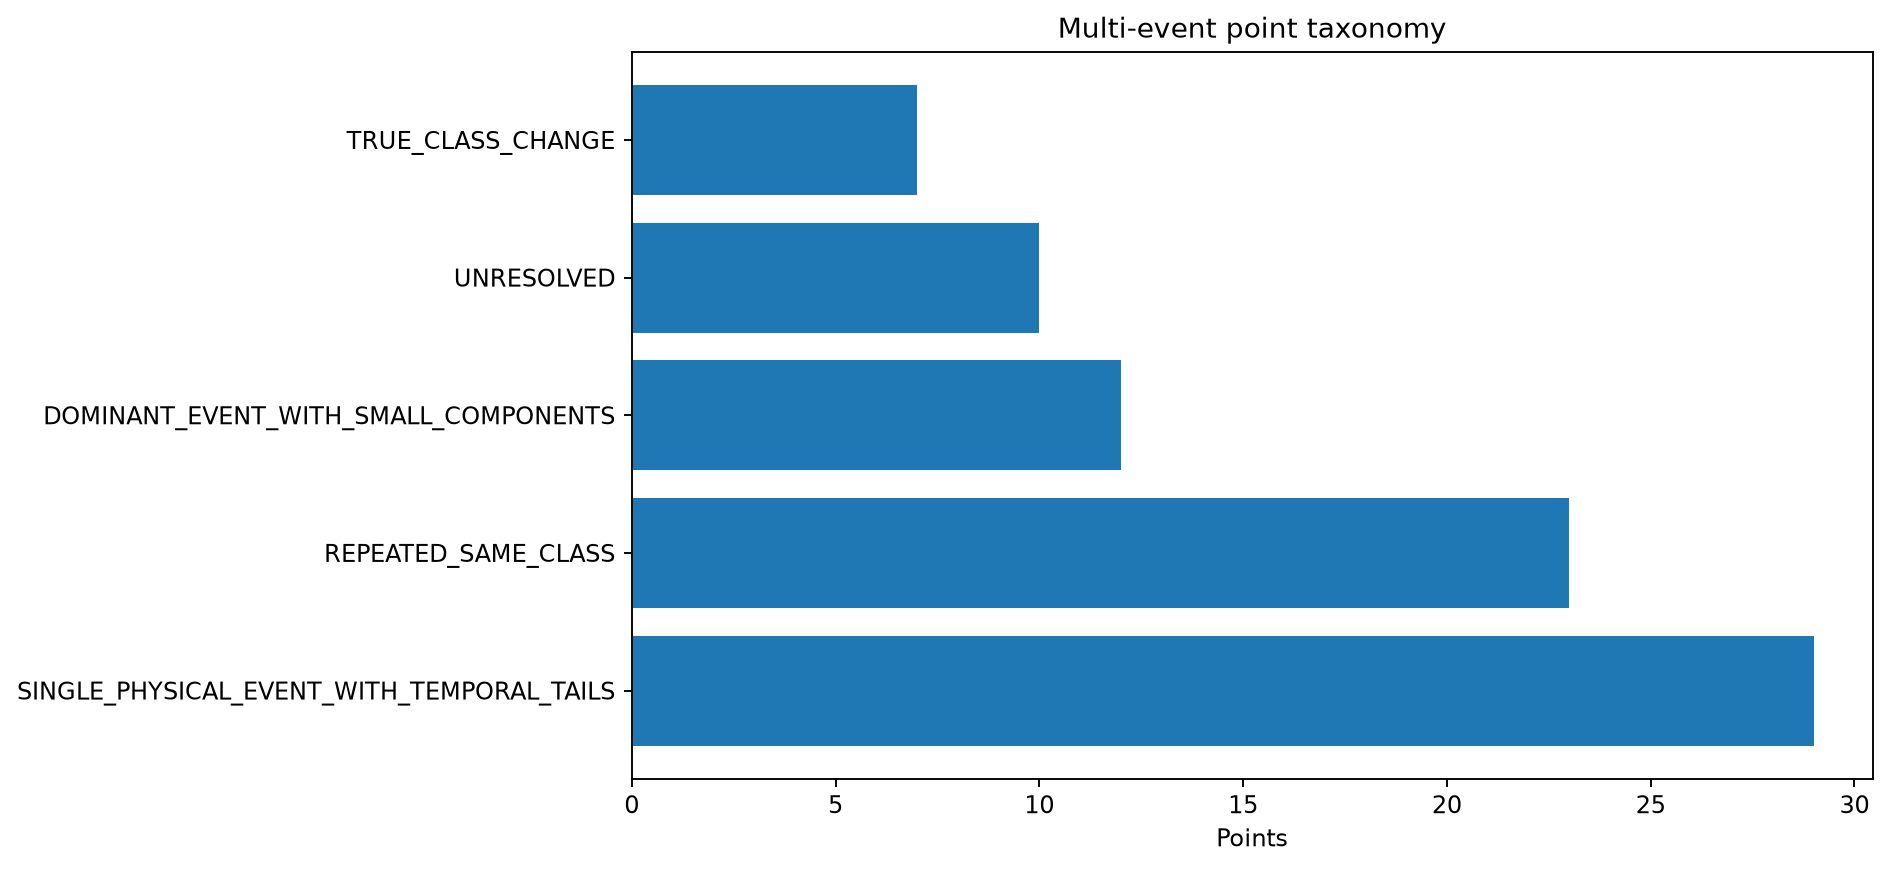

### Paired Model Performance

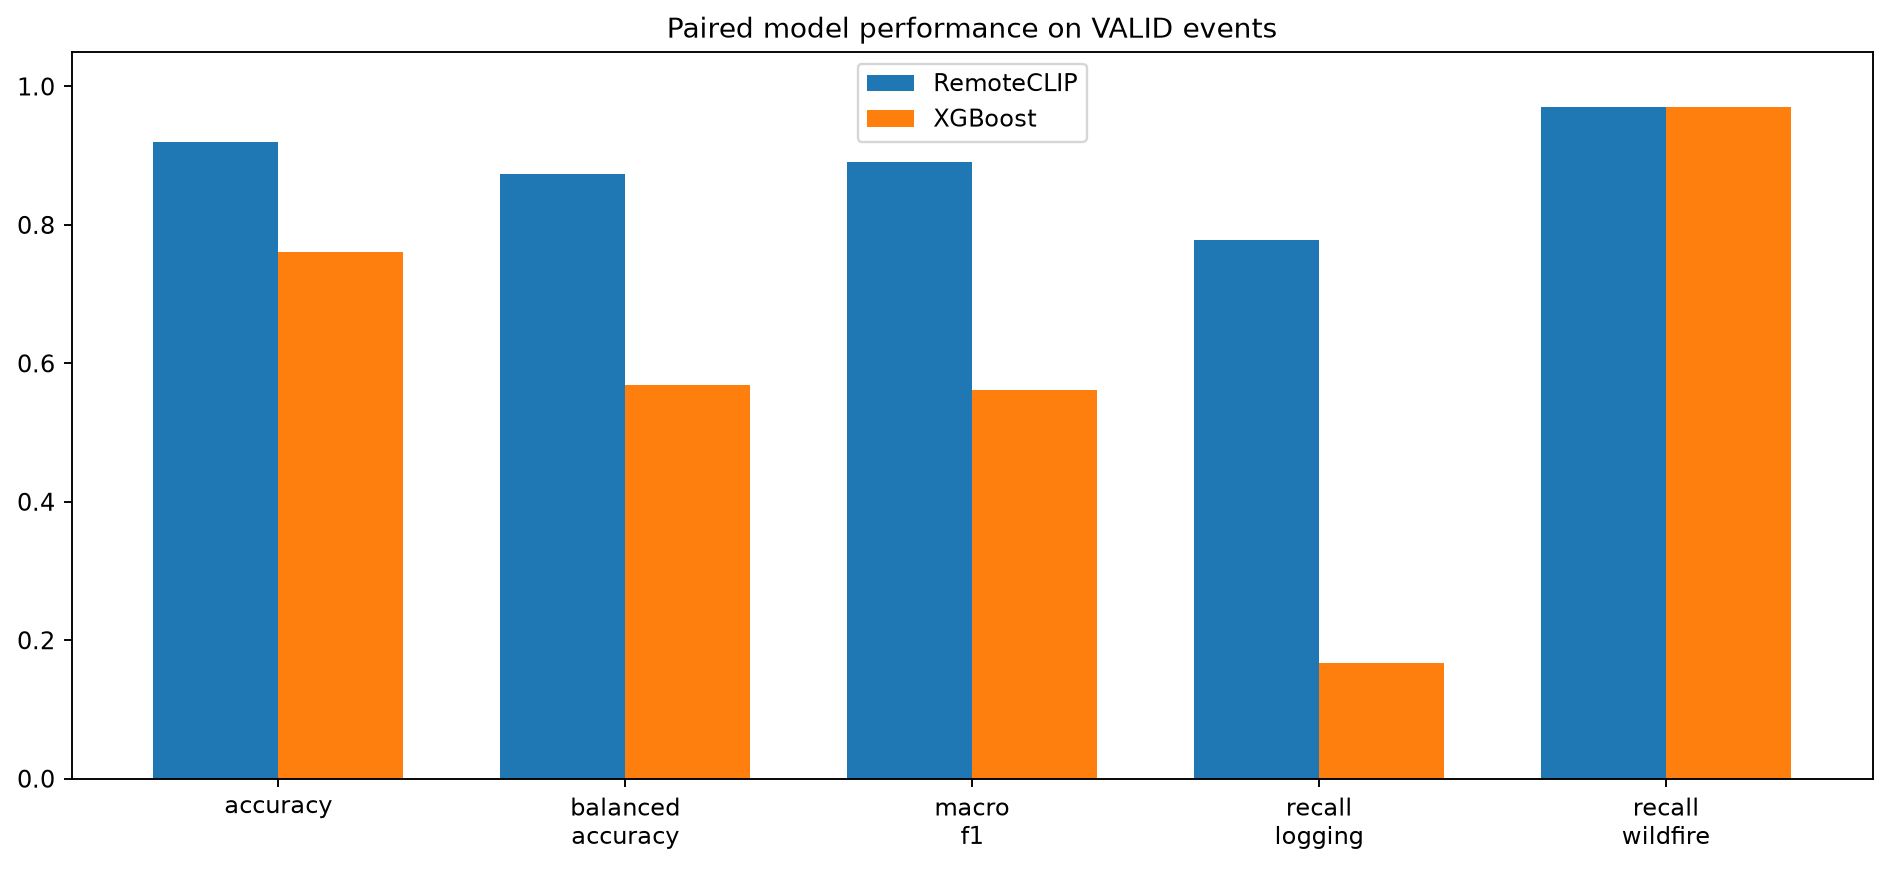

### Relative Area By Review Class

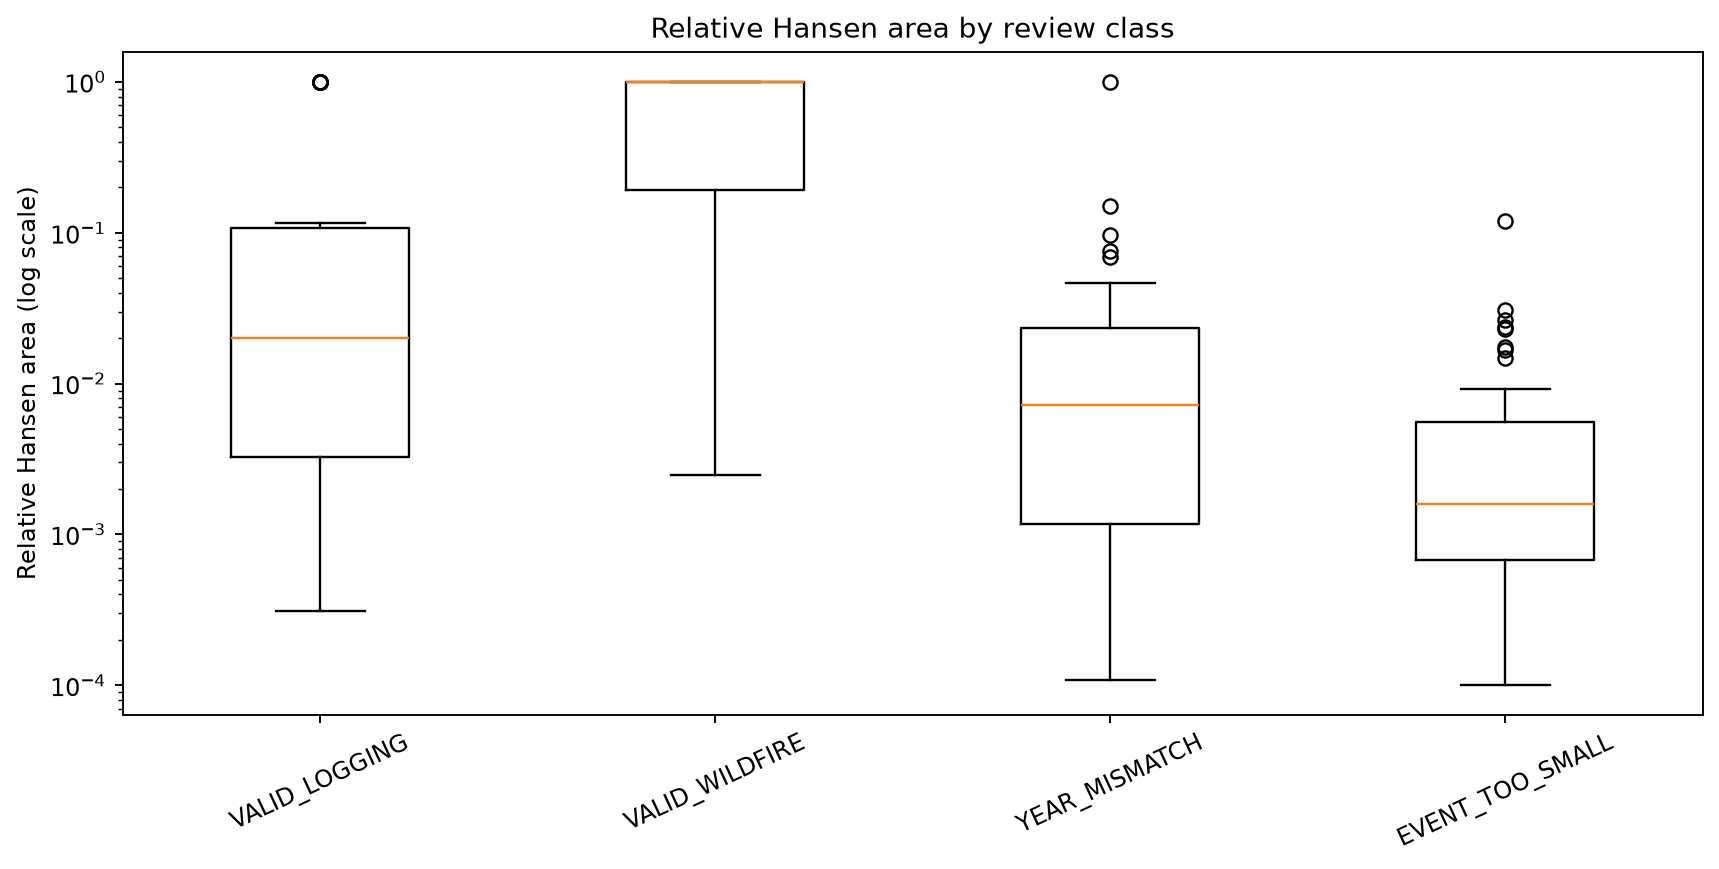

### Remoteclip Probability By Delta

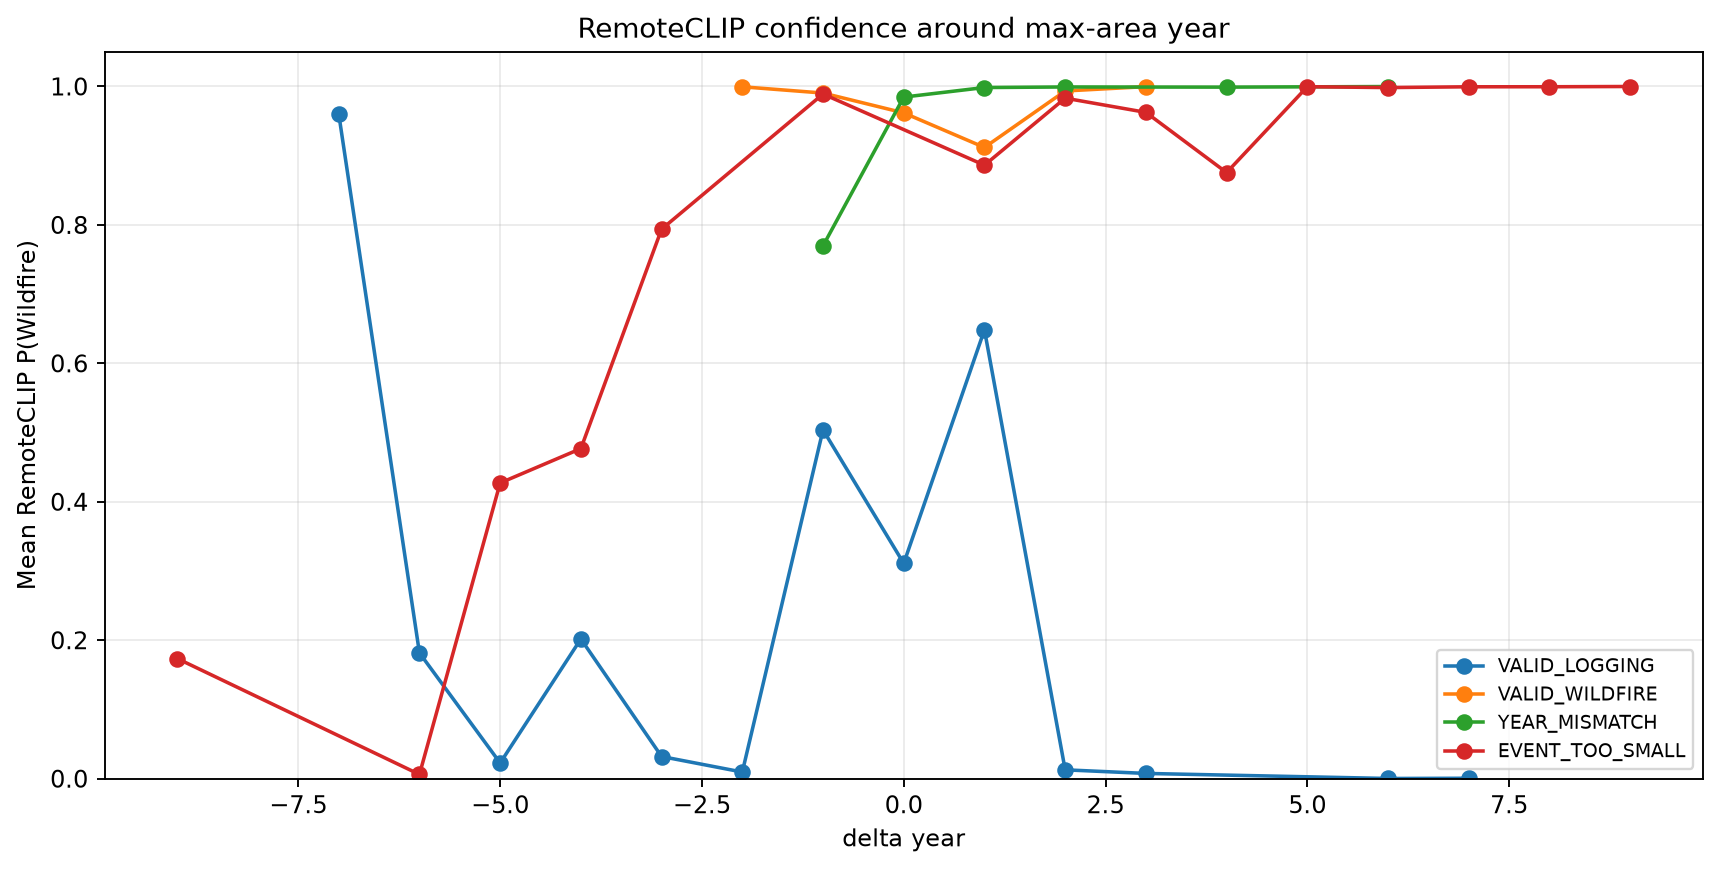

### Review Class By Delta Year

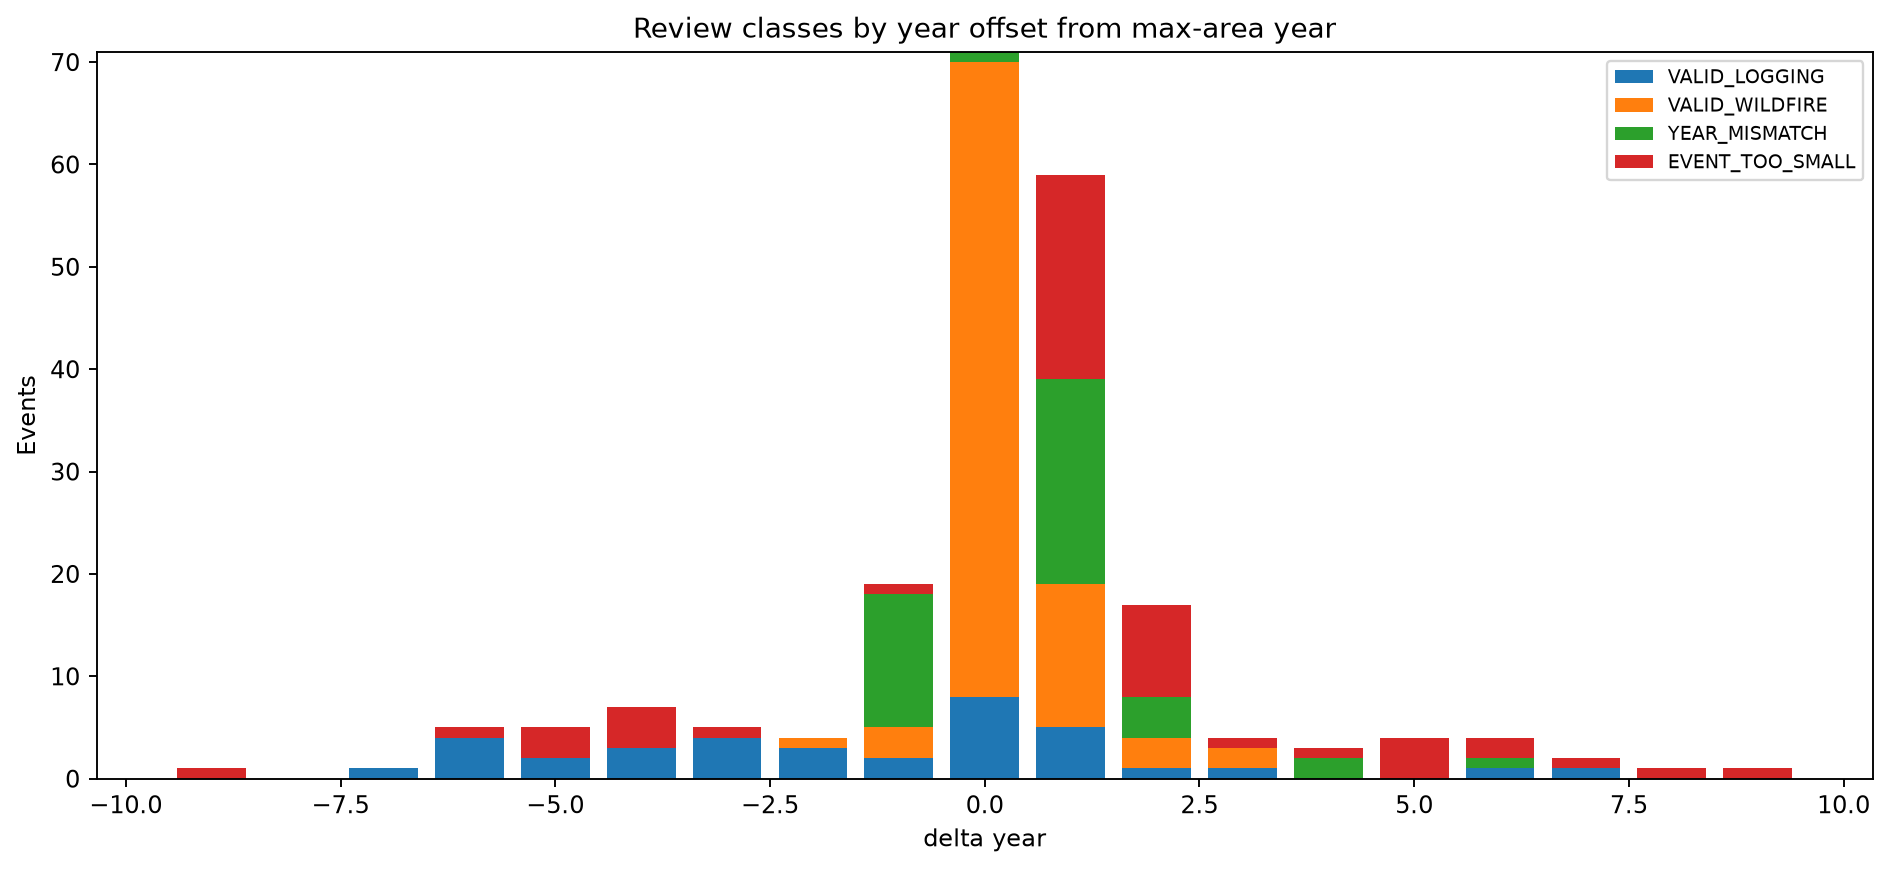

### Review Hierarchy Distribution

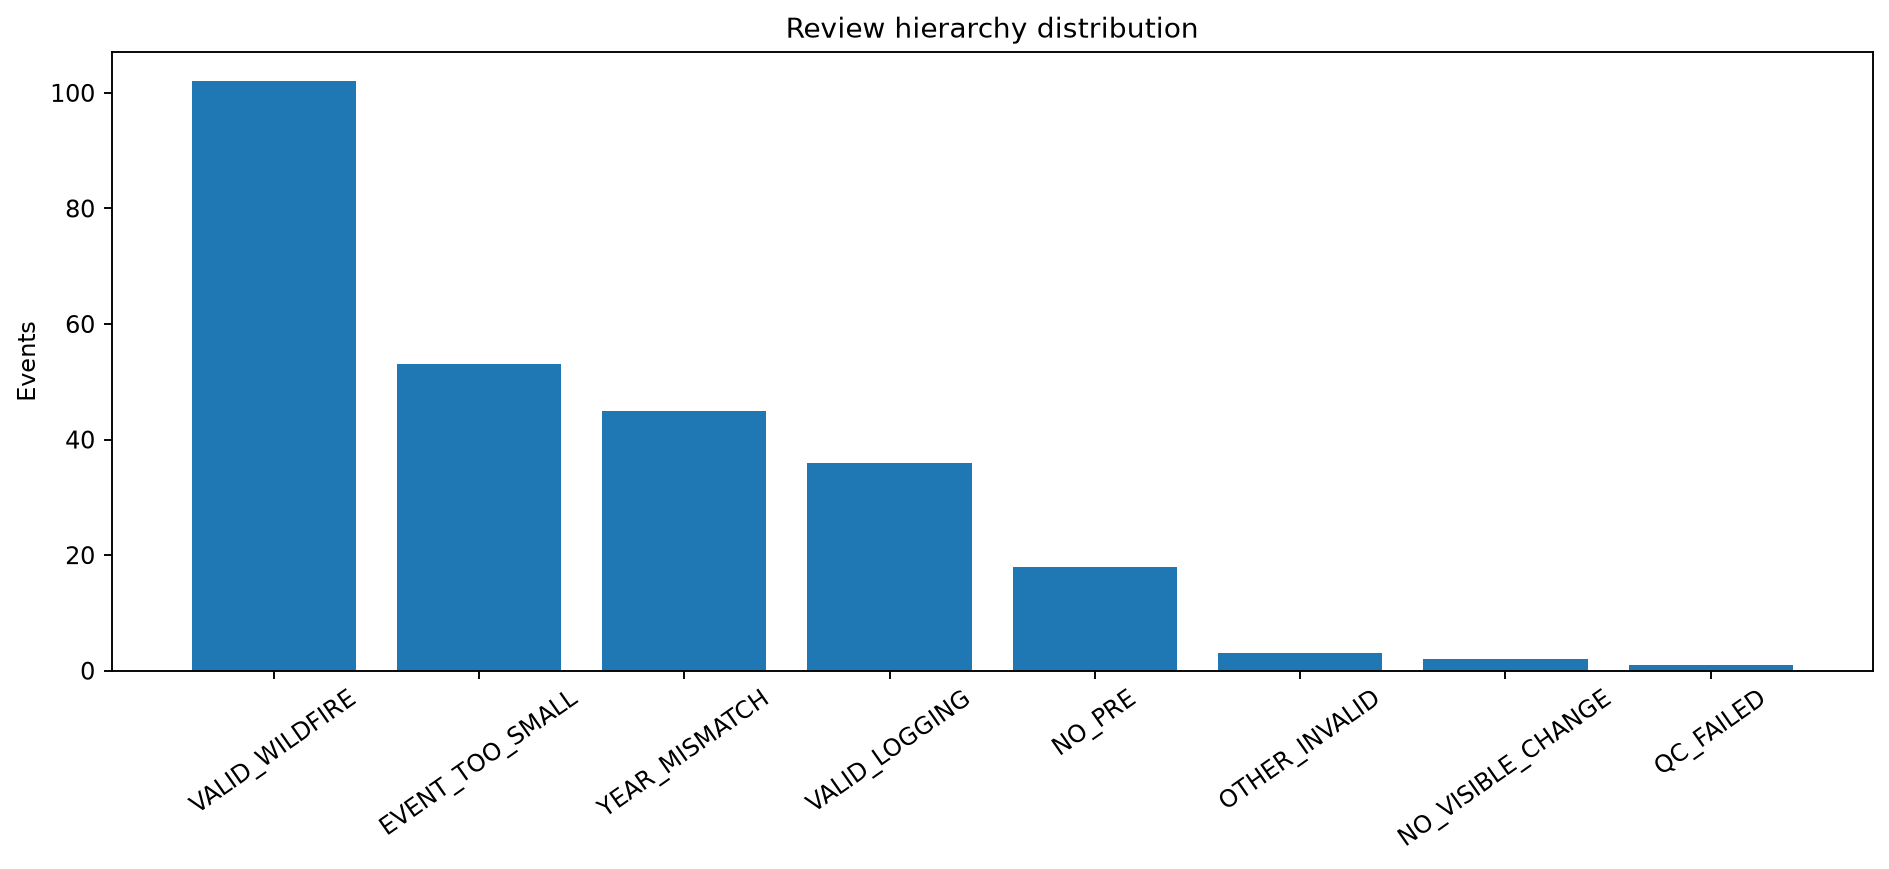

### Valid Probability By Delta

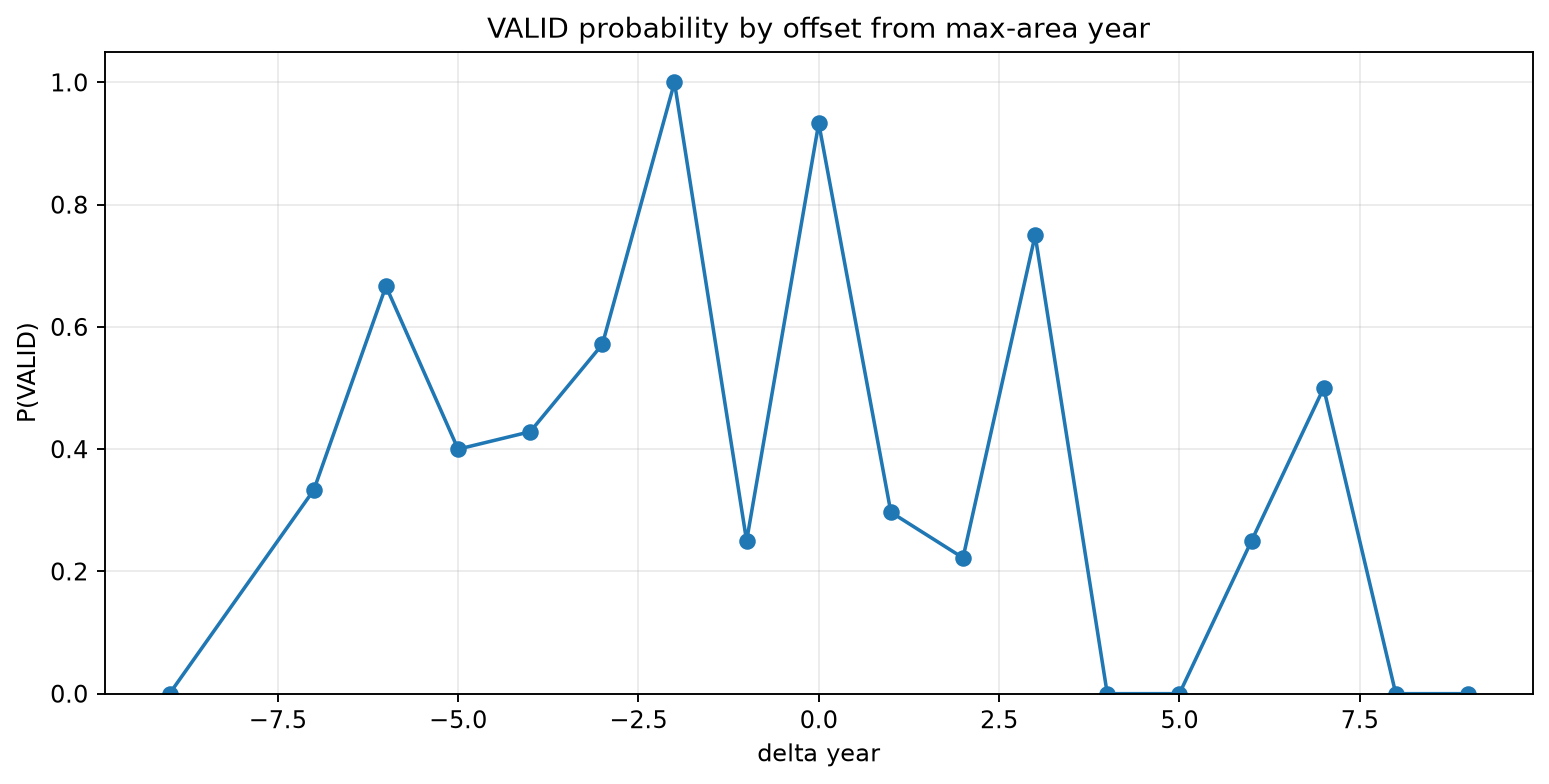

### Year Mismatch Timelines

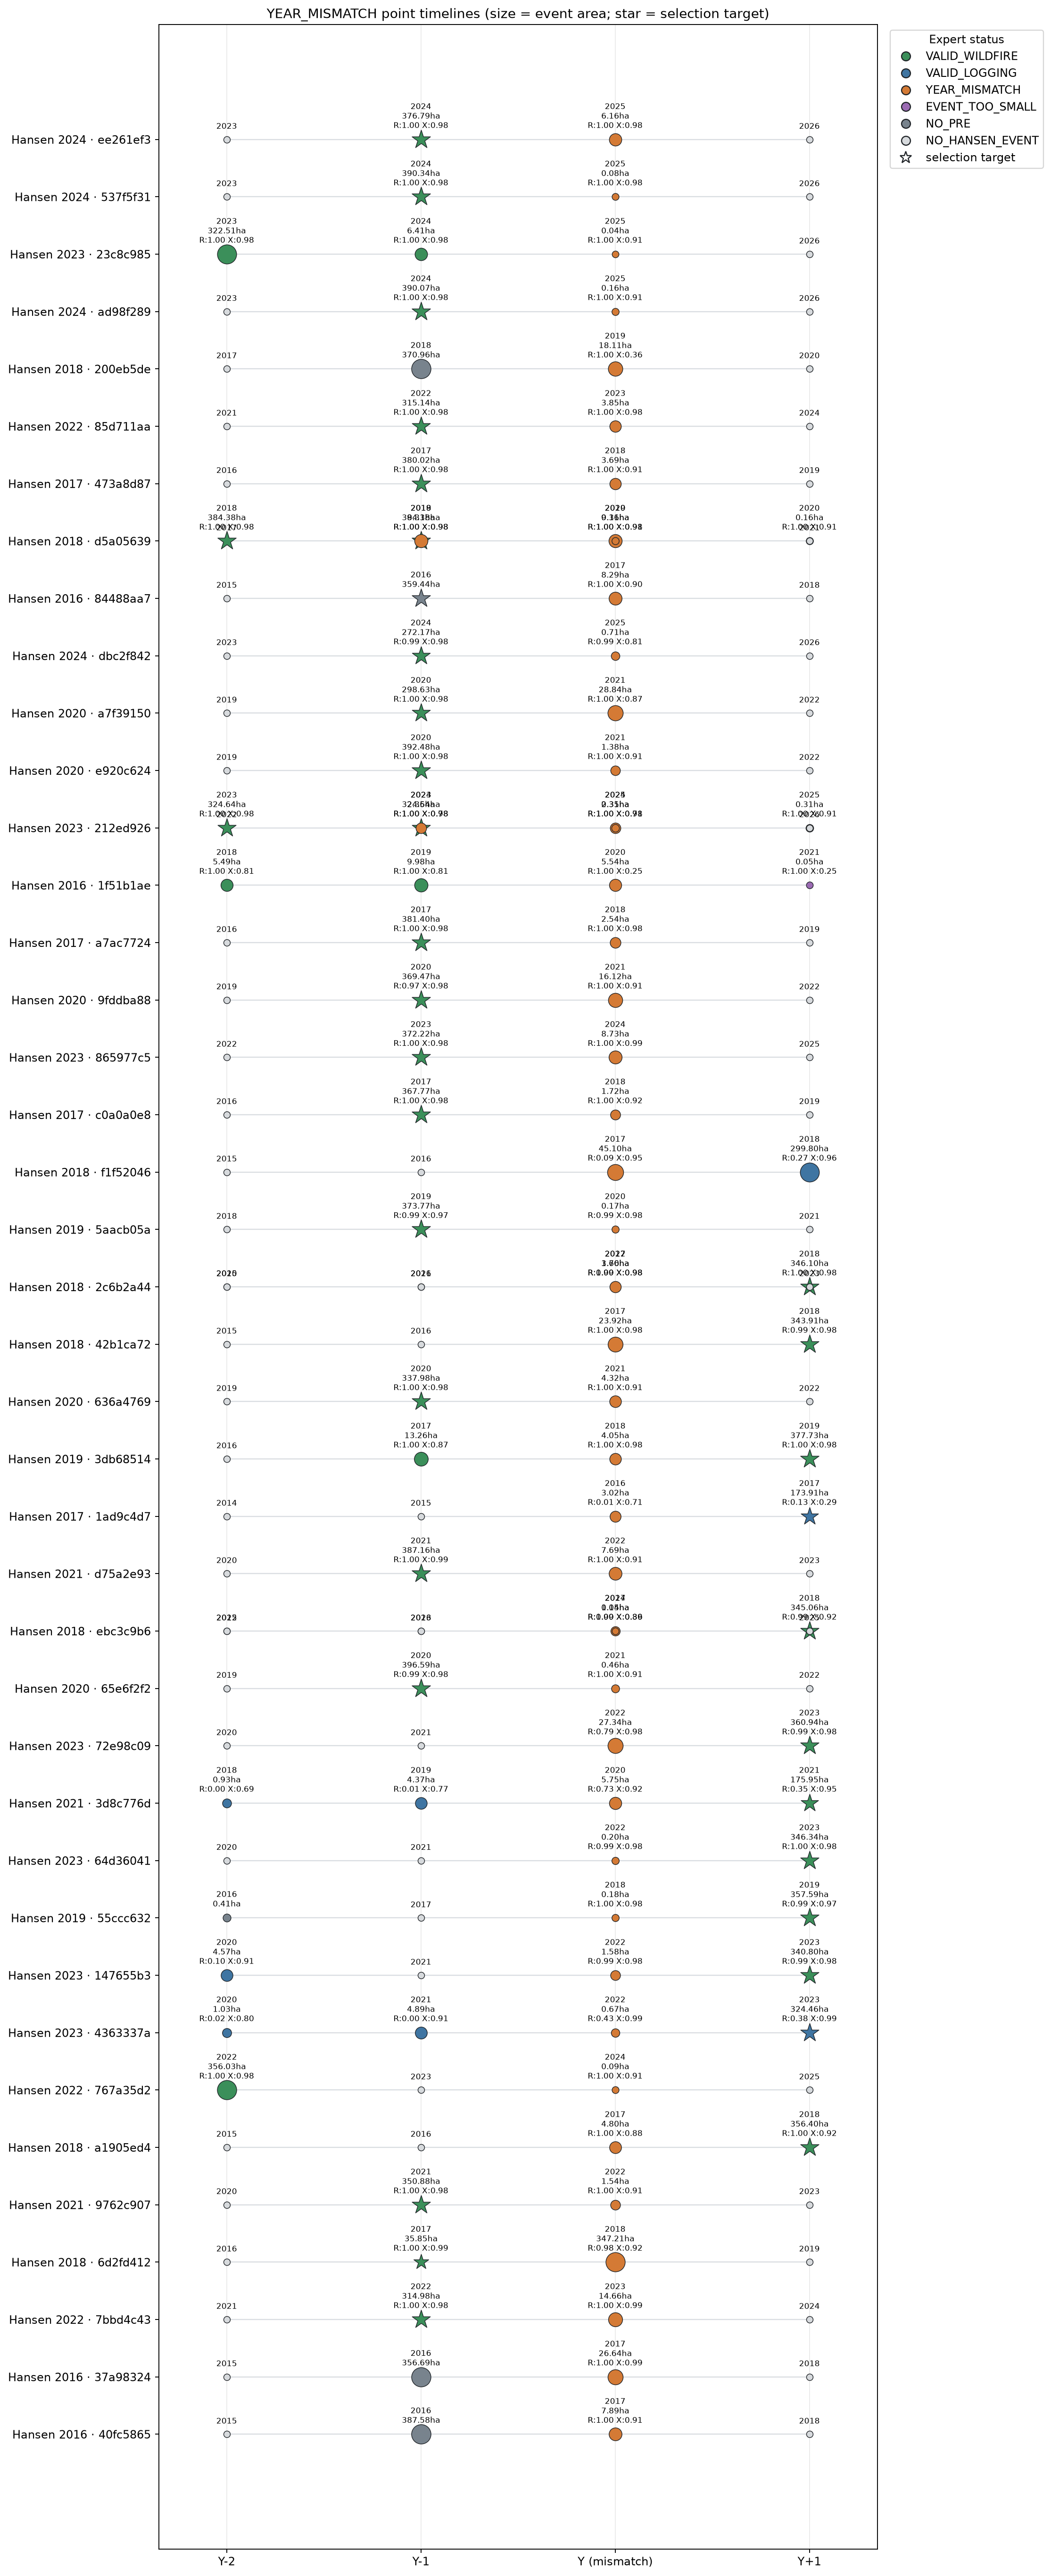

In [10]:
for image_path in sorted((run_dir / 'plots').glob('*.png')):
    display(Markdown(f'### {image_path.stem.replace("_", " ").title()}'))
    display(Image(filename=str(image_path)))

## Final report

The report below is also saved as `REPORT.md` together with all machine-readable tables and figures.

In [11]:
display(Markdown(Path(result['report_path']).read_text(encoding='utf-8')))

# Multi-event Hansen structure and model validation

## Research cohort

- Reviewed events: **260**.
- Reviewed points: **99**.
- VALID / REJECTED events: **138 / 122**.
- Multi-event points: **81** (81.8%).

All confidence intervals, paired tests, and cross-validation procedures use `sample_id` as the resampling/grouping unit. Events from the same point are never treated as independent observations.

## Human review hierarchy

| Class | Events | Share |
|---|---:|---:|
| VALID_WILDFIRE | 102 | 39.2% |
| EVENT_TOO_SMALL | 53 | 20.4% |
| YEAR_MISMATCH | 45 | 17.3% |
| VALID_LOGGING | 36 | 13.8% |
| NO_PRE | 18 | 6.9% |
| OTHER_INVALID | 3 | 1.2% |
| NO_VISIBLE_CHANGE | 2 | 0.8% |
| QC_FAILED | 1 | 0.4% |

Rejected events are not classification errors. `NO_PRE` and `QC_FAILED` remain acquisition-pipeline failures and are excluded from validity classifiers.

## Paired RemoteCLIP vs XGBoost comparison

Paired grouped bootstrap uses **138 valid events** from **92 points** and the same sampled points for both models.

| Metric | RemoteCLIP | XGBoost | Point delta | Bootstrap mean delta | 95% CI | P(delta > 0) |
|---|---:|---:|---:|---:|---:|---:|
| accuracy | 0.920 | 0.761 | 0.159 | 0.159 | [0.073, 0.250] | 100.0% |
| balanced_accuracy | 0.874 | 0.569 | 0.306 | 0.313 | [0.185, 0.436] | 100.0% |
| macro_f1 | 0.892 | 0.562 | 0.330 | 0.349 | [0.171, 0.505] | 100.0% |
| recall_logging | 0.778 | 0.167 | 0.611 | 0.626 | [0.375, 0.862] | 100.0% |
| recall_wildfire | 0.971 | 0.971 | 0.000 | -0.001 | [-0.062, 0.064] | 42.5% |

### Joint outcomes

| Outcome | Events | Share |
|---|---:|---:|
| BOTH_CORRECT | 102 | 73.9% |
| REMOTECLIP_ONLY_CORRECT | 25 | 18.1% |
| BOTH_WRONG | 8 | 5.8% |
| XGBOOST_ONLY_CORRECT | 3 | 2.2% |

## Independent validation of frozen EVENT_TOO_SMALL rules

The thresholds are evaluated only on the **50 points / 158 events** added after the original 49-point analysis. They were not re-optimized before this test.

| Rule | Precision | Recall | Specificity | F1 | VALID lost |
|---|---:|---:|---:|---:|---:|
| `event_loss_area_ha <= 3.285` | 0.500 | 0.838 | 0.744 | 0.626 | 14 (16.7%) |
| `event_hansen_pixels <= 84.0` | 0.517 | 0.838 | 0.760 | 0.639 | 13 (15.5%) |
| `hansen_loss_aoi_percent <= 0.821` | 0.500 | 0.838 | 0.744 | 0.626 | 14 (16.7%) |
| `ANY_FIXED_THRESHOLD` | 0.500 | 0.838 | 0.744 | 0.626 | 14 (16.7%) |

The frozen signal generalizes, but it is not safe as a hard auto-reject rule: the combined rule retains 83.8% recall while discarding 16.7% of human-VALID holdout events. It should be used for review priority or as one feature in a conditional grouping model.

## Multi-event point taxonomy

Taxonomy priority is `TRUE_CLASS_CHANGE -> REPEATED_SAME_CLASS -> temporal tails -> small components -> UNRESOLVED`; overlapping boolean flags are preserved in the point-level artifact.

| Point type | Points | Share of multi-event | Mean Hansen events |
|---|---:|---:|---:|
| SINGLE_PHYSICAL_EVENT_WITH_TEMPORAL_TAILS | 29 | 35.8% | 2.41 |
| REPEATED_SAME_CLASS | 23 | 28.4% | 3.74 |
| DOMINANT_EVENT_WITH_SMALL_COMPONENTS | 12 | 14.8% | 2.42 |
| UNRESOLVED | 10 | 12.3% | 2.10 |
| TRUE_CLASS_CHANGE | 7 | 8.6% | 5.14 |

Tail/small-component types contain **41 points**; repeated or class-change types contain **30 points**. This is descriptive evidence, not an automatic physical-event ground truth.

## Dominant-year ranking

The target is a set of all human-VALID years per point; a point with two real VALID events is not forced to one target year.

| Method | Points | Hit@1 | Hit@2 | MRR | Median target rank | Mean year error |
|---|---:|---:|---:|---:|---:|---:|
| HAND_BUILT_COMPOSITE | 75 | 0.907 | 1.000 | 0.953 | 1.000 | 0.227 |
| HISTORICAL_DOMINANT | 75 | 0.933 | 0.973 | 0.962 | 1.000 | 0.093 |
| LOPO_LOGISTIC_REGRESSION | 75 | 0.933 | 0.987 | 0.963 | 1.000 | 0.080 |
| MAX_HANSEN_AREA | 75 | 0.933 | 0.973 | 0.962 | 1.000 | 0.093 |
| MAX_MODEL_MEAN_P_WILDFIRE | 75 | 0.773 | 0.987 | 0.883 | 1.000 | 0.413 |

Best current Hit@1: **LOPO_LOGISTIC_REGRESSION = 93.3%**. Methods select different years on **34 points**.

## Dominant-relative evidence (MAX_HANSEN_AREA)

| Quantity | Estimate | 95% point-clustered CI | Events |
|---|---:|---:|---:|
| P(VALID | delta=0) | 0.933 | [0.867, 0.987] | 75 |
| P(VALID | |delta|=1) | 0.286 | [0.192, 0.378] | 84 |
| P(YEAR_MISMATCH | |delta|=1) | 0.393 | [0.299, 0.494] | 84 |
| P(EVENT_TOO_SMALL | |delta|=1) | 0.250 | [0.163, 0.333] | 84 |

## Candidate adjacent-year merge simulation

Rule: `adjacent year and relative area <= 0.5`. Human review is used only to score proposed merges.

| Proposed | GOOD | BAD | UNRESOLVED | Precision among resolved | Recall of identifiable tails | Groups before | Groups after |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 126 | 65 | 32 | 29 | 0.670 | 0.970 | 242 | 116 |

## Spatial connectivity of adjacent Hansen components

Status: **ok**; geometry pairs: **132**; points with masks: **79**.

| Pair type | Pairs | Median minimum distance, m | Median centroid distance, m | Touching after 1 px | Touching after 2 px | Median relative area |
|---|---:|---:|---:|---:|---:|---:|
| OTHER | 30 | 15.7 | 459.7 | 86.7% | 90.0% | 0.036 |
| VALID_PLUS_EVENT_TOO_SMALL | 28 | 15.3 | 507.3 | 96.4% | 96.4% | 0.008 |
| VALID_PLUS_VALID_SAME_CLASS | 35 | 16.2 | 485.1 | 77.1% | 80.0% | 0.104 |
| VALID_PLUS_YEAR_MISMATCH | 39 | 14.0 | 535.6 | 97.4% | 100.0% | 0.012 |

## Acquisition and exploratory validity diagnostics

`NO_PRE` and `QC_FAILED` are reported as pipeline losses, not semantic invalidity.

| Pipeline reason | Events | Points |
|---|---:|---:|
| NO_PRE | 18 | 16 |
| QC_FAILED | 1 | 1 |

Exploratory VALID-vs-REJECTED models: status **ok**. Grouped-CV metrics are exported separately and must not be interpreted as production performance.

## Main hypothesis assessment

Current evidence is **mixed** for conditional temporal grouping. The dominant-relative pattern strongly supports temporal tails, but the simple merge rule would combine 32 genuinely VALID pairs (25.4% of proposals), so automatic merging is unsafe. The result does not justify merging every adjacent Hansen year. Real repeated events and class changes remain explicit counterexamples and must stay separate.

Recommended pipeline order remains:

`Acquisition QC -> EVENT_TOO_SMALL screening -> temporal/EventGroup analysis -> dominant-year ranking -> RemoteCLIP/XGBoost -> knownness/disagreement -> manual review`.

FIRMS data are not integrated; corresponding fields remain unavailable rather than being inferred.

## Artifacts

- `event_level_summary.csv` and `multi_event_points.csv`.
- `paired_model_comparison.csv` and `paired_bootstrap_deltas.csv`.
- `fixed_small_event_validation.csv`.
- `dominant_year_ranking.csv`, `dominant_year_point_predictions.csv`.
- `dominant_relative_events.csv`, `dominant_relative_summary.csv`, and bootstrap headlines.
- `merge_simulation_pairs.csv`.
- `spatial_connectivity_pairs.csv` and `spatial_connectivity_summary.csv`.
- `plots/` contains the requested summary figures.

Base rejection/knownness/acquisition report: `rejection_diagnostics/20261115_143435`.